# fairmeasure demo

Walkthrough of everything the module does, using a made-up loan-approval problem:

1. a unified `FairnessAnalyzer` over fairlearn + aequitas
2. classification metrics with bootstrap CIs, effect sizes and group sizes
3. intersectional groups and `min_group_size`
4. multiple-comparison correction (Benjamini-Hochberg)
5. regression and ranking
6. MLflow logging, `assert_fairness` for CI, and plots

The data is synthetic so you can see the bias we planted come back out of the numbers.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from fairmeasure import (FairnessAnalyzer, assert_fairness, log_to_mlflow,
                         plot_report, save_report_plots, METRICS)

rng = np.random.default_rng(2024)

## 1. Make some data

Applicants have a sex, a race (group D is deliberately tiny) and a few financial features.
Whether they actually repay (`repaid`) depends only on the features. The *historical*
approvals the model learns from are biased though: women and race C were approved less often
than their finances justify, and two innocent-looking features leak group membership (`neighbourhood` leaks race, `career_gap` leaks sex). So the model picks up the bias.

In [2]:
n = 6000
df = pd.DataFrame({
    "sex": rng.choice(["F", "M"], n),
    "race": rng.choice(["A", "B", "C", "D"], n, p=[0.50, 0.30, 0.185, 0.015]),
})
df["income"] = rng.normal(0, 1, n)
df["debt_ratio"] = rng.normal(0, 1, n)
df["history"] = rng.normal(0, 1, n)
# proxy that correlates with race
df["neighbourhood"] = rng.normal(0, 0.6, n) - 1.5 * (df["race"] == "C") - 0.6 * (df["race"] == "B")
# proxy that correlates with sex (think "years out of the workforce")
df["career_gap"] = rng.normal(0, 0.6, n) + 1.5 * (df["sex"] == "F")

signal = 1.0 * df.income - 0.8 * df.debt_ratio + 0.7 * df.history
df["repaid"] = (rng.random(n) < 1 / (1 + np.exp(-signal))).astype(int)

bias = -1.5 * (df.sex == "F") - 1.0 * (df.race == "C")
df["hist_approved"] = (rng.random(n) < 1 / (1 + np.exp(-(signal + bias)))).astype(int)

features = ["income", "debt_ratio", "history", "neighbourhood", "career_gap"]
train, test = train_test_split(df, test_size=0.4, random_state=0)
model = LogisticRegression().fit(train[features], train["hist_approved"])

y_true = test["repaid"].to_numpy()
y_pred = model.predict(test[features])
sensitive = test[["sex", "race"]]
print(len(test), "test rows, approval rate", y_pred.mean().round(3))
test.groupby("sex")["repaid"].size()

2400 test rows, approval rate 0.27


sex
F    1161
M    1239
Name: repaid, dtype: int64

## 2. Classification metrics

One class does everything. The metrics default to demographic parity and equalized odds
(both computed by **fairlearn**). `n_bootstrap=200` keeps the demo quick, use 1000+ for real reports.

In [3]:
analyzer = FairnessAnalyzer(task="classification", n_bootstrap=200, min_group_size=30, random_state=0)
report = analyzer.analyze(y_true, y_pred, sensitive["sex"])
print(report)

demographic_parity_difference [sex] = 0.1852 (95% CI 0.1539 to 0.2214), risk_ratio = 2.064
equalized_odds_difference [sex] = 0.2714 (95% CI 0.2095 to 0.3208), risk_ratio = 1.945


Each result is a structured object, not just a number:

In [4]:
r = report.get("demographic_parity_difference")
print("value        :", round(r.value, 4))
print("95% CI       :", (round(r.ci_low, 4), round(r.ci_high, 4)))
print("effect size  :", r.effect_size.name, round(r.effect_size.value, 3),
      "CI", (round(r.effect_size.ci_low, 3), round(r.effect_size.ci_high, 3)))
print("group sizes  :", r.group_sizes)
print("group values :", {k: round(v, 3) for k, v in r.group_values.items()}, "<-", r.effect_size.basis)
print("backend      :", r.backend)

value        : 0.1852
95% CI       : (0.1539, 0.2214)
effect size  : risk_ratio 2.064 CI (1.838, 2.394)
group sizes  : {'F': 1161, 'M': 1239}
group values : {'F': 0.174, 'M': 0.359} <- selection_rate
backend      : fairlearn


In [5]:
report.to_frame().round(4)

,metric,attribute,backend,value,ci_low,ci_high,effect_size,effect_name,effect_ci_low,effect_ci_high,p_value,p_adjusted,n_groups,n_excluded_groups
0,demographic_parity_difference,sex,fairlearn,0.1852,0.1539,0.2214,2.0643,risk_ratio,1.8382,2.394,None,None,2,0
1,equalized_odds_difference,sex,fairlearn,0.2714,0.2095,0.3208,1.9452,risk_ratio,1.6689,2.252,None,None,2,0


Reading it: women are approved noticeably less often than men, the CI stays well away from 0,
and the risk ratio says men are approved at roughly twice the rate of women. That's the planted bias showing up.

## 3. Delegation across libraries

`backend="auto"` sends each metric to whichever library handles it. `fpr_difference` and `fdr_difference`
go to **aequitas**, the demographic parity / equalized odds ones to **fairlearn**. You never import either.

In [6]:
print(sorted(METRICS))
a2 = FairnessAnalyzer(
    metrics=["demographic_parity_difference", "equalized_odds_difference",
             "equal_opportunity_difference", "fpr_difference", "fdr_difference"],
    n_bootstrap=100, random_state=0,
)
rep2 = a2.analyze(y_true, y_pred, sensitive["sex"])
rep2.to_frame()[["metric", "backend", "value", "ci_low", "ci_high", "effect_size"]].round(4)

['demographic_parity_difference', 'equal_opportunity_difference', 'equalized_odds_difference', 'exposure_parity_difference', 'fdr_difference', 'fpr_difference', 'mae_difference']


,metric,backend,value,ci_low,ci_high,effect_size
0,demographic_parity_difference,fairlearn,0.1852,0.1547,0.2184,2.0643
1,equalized_odds_difference,fairlearn,0.2714,0.2165,0.3212,1.9452
2,equal_opportunity_difference,fairlearn,0.2714,0.2116,0.3178,1.9452
3,fpr_difference,aequitas,0.0982,0.0651,0.1387,2.8393
4,fdr_difference,aequitas,0.0582,0.0084,0.1202,1.3921


You can also force a backend, and the numpy fallback gives the same answer as the libraries:

In [7]:
for backend in ["fairlearn", "native"]:
    a = FairnessAnalyzer(metrics=["equalized_odds_difference"], backend=backend, n_bootstrap=20, random_state=0)
    print(backend, round(a.analyze(y_true, y_pred, sensitive["sex"]).results[0].value, 6))

fairlearn 0.271399
native 0.271399


## 4. Intersectional groups and `min_group_size`

Passing several columns analyses each one and, with `intersectional=True`, the combinations too.
Group D is tiny, so the sex x race cells for D have only a handful of rows. With `min_group_size=30`
they are dropped from the calculation and listed under `excluded_groups` instead of producing a noisy number.

In [8]:
inter = FairnessAnalyzer(n_bootstrap=150, min_group_size=30, random_state=0)
rep_i = inter.analyze(y_true, y_pred, sensitive, intersectional=True)
rep_i.to_frame()[["metric", "attribute", "value", "ci_low", "ci_high", "effect_size", "n_groups", "n_excluded_groups"]].round(3)

,metric,attribute,value,ci_low,ci_high,effect_size,n_groups,n_excluded_groups
0,demographic_parity_difference,sex,0.185,0.155,0.218,2.064,2,0
1,equalized_odds_difference,sex,0.271,0.219,0.318,1.945,2,0
2,demographic_parity_difference,race,0.088,0.061,0.228,1.405,4,0
3,equalized_odds_difference,race,0.133,0.107,0.338,1.372,4,0
4,demographic_parity_difference,sex & race,0.266,0.222,0.318,2.796,6,2
5,equalized_odds_difference,sex & race,0.400,0.343,0.496,2.821,6,2


In [9]:
combo = rep_i.get("demographic_parity_difference", "sex & race")
print("kept    :", combo.group_sizes)
print("dropped :", combo.excluded_groups)

kept    : {'sex=F & race=A': 591, 'sex=F & race=B': 351, 'sex=F & race=C': 196, 'sex=M & race=A': 602, 'sex=M & race=B': 384, 'sex=M & race=C': 239}
dropped : {'sex=F & race=D': 23, 'sex=M & race=D': 14}


What happens without the guard? Same data, `min_group_size=1`: the tiny cells sneak in, the point estimate jumps and the interval gets about 3-4x wider.

In [10]:
unguarded = FairnessAnalyzer(n_bootstrap=150, min_group_size=1, random_state=0)
u = unguarded.analyze(y_true, y_pred, sensitive, intersectional=True).get("demographic_parity_difference", "sex & race")
print(f"guarded  : {combo.value:.3f}  CI width {combo.ci_high - combo.ci_low:.3f}")
print(f"unguarded: {u.value:.3f}  CI width {u.ci_high - u.ci_low:.3f}  ({len(u.group_sizes)} groups)")

guarded  : 0.266  CI width 0.096
unguarded: 0.298  CI width 0.351  (8 groups)


## 5. Is it just noise? Statistical validation

Two things guard against over-reading a number:

* the **bootstrap CI** (percentile method, rows resampled with replacement) shows how much the metric would wobble on a different sample
* the **effect size** (risk ratio) says how big the gap is in practical terms. A tiny gap can be "significant" with enough data, and a big gap can have a wide CI on small data

Here's the CI shrinking as we feed it more rows from the same population:

In [11]:
rows = []
for size in [200, 800, 3200]:
    idx = rng.choice(len(test), size=size, replace=True)
    a = FairnessAnalyzer(metrics=["demographic_parity_difference"], n_bootstrap=150,
                         min_group_size=10, random_state=0, backend="native")
    res = a.analyze(y_true[idx], y_pred[idx], sensitive["sex"].to_numpy()[idx]).results[0]
    rows.append({"n": size, "value": res.value, "ci_low": res.ci_low, "ci_high": res.ci_high,
                 "width": res.ci_high - res.ci_low})
pd.DataFrame(rows).round(3)

,n,value,ci_low,ci_high,width
0,200,0.270,0.169,0.379,0.210
1,800,0.133,0.078,0.179,0.101
2,3200,0.199,0.167,0.229,0.062


## 6. Multiple comparisons (Benjamini-Hochberg)

Test enough sensitive attributes, metrics and intersections and something will look "unfair" by luck.
`correction="benjamini-hochberg"` computes a permutation p-value for each result (shuffling group labels)
and adjusts them across the whole report.

In [12]:
bh = FairnessAnalyzer(n_bootstrap=100, min_group_size=30, correction="benjamini-hochberg",
                      n_permutations=1000, random_state=0)
rep_bh = bh.analyze(y_true, y_pred, sensitive, intersectional=True)
rep_bh.to_frame()[["metric", "attribute", "value", "p_value", "p_adjusted"]].round(4)

,metric,attribute,value,p_value,p_adjusted
0,demographic_parity_difference,sex,0.1852,0.0010,0.0015
1,equalized_odds_difference,sex,0.2714,0.0010,0.0015
2,demographic_parity_difference,race,0.0884,0.3317,0.3980
3,equalized_odds_difference,race,0.1331,0.4096,0.4096
4,demographic_parity_difference,sex & race,0.2657,0.0010,0.0015
5,equalized_odds_difference,sex & race,0.4002,0.0010,0.0015


## 7. Regression

Fairness for a continuous prediction: here a salary model that is much noisier for one group.
The metric is the gap in mean absolute error, the effect size is the ratio of the group MAEs.

In [13]:
m = 3000
grp = rng.choice(["north", "south", "east"], m, p=[0.5, 0.3, 0.2])
actual = rng.normal(50, 10, m)
predicted = actual + rng.normal(0, 1, m) * np.where(grp == "south", 6.0, 3.0)

reg = FairnessAnalyzer(task="regression", n_bootstrap=200, random_state=0)
reg_report = reg.analyze(actual, predicted, grp)
print(reg_report)
reg_report.results[0].group_values

mae_difference [group] = 2.4681 (95% CI 2.2310 to 2.7552), error_ratio = 2.039


{'east': 2.375893126529338,
 'north': 2.4248520773440365,
 'south': 4.844037469903428}

## 8. Ranking (exposure parity)

For a ranked list, items near the top get more attention. Exposure at rank r is `1/log2(1+r)`; the metric is the gap
in average exposure per item between groups. Pass the ranking scores as `y_pred` and `None` for `y_true`.

In [14]:
k = 2000
rg = rng.choice(["a", "b"], k, p=[0.6, 0.4])
scores = rng.normal(size=k) - 0.5 * (rg == "b")      # group b gets pushed down the list

rank_an = FairnessAnalyzer(task="ranking", n_bootstrap=200, min_group_size=30, random_state=0)
rank_report = rank_an.analyze(None, scores, rg)
print(rank_report)

exposure_parity_difference [group] = 0.0092 (95% CI 0.0067 to 0.0114), exposure_ratio = 1.089


## 9. MLflow

`log_to_mlflow` writes every value, CI bound, effect size, p-value and group size as MLflow metrics on the active run,
plus the whole report as a JSON artifact. (Using a throwaway sqlite store here.)

In [15]:
import os, logging, pathlib, tempfile
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import mlflow
logging.getLogger("mlflow").setLevel(logging.ERROR)

tmp = tempfile.mkdtemp()
mlflow.set_tracking_uri("sqlite:///" + os.path.join(tmp, "mlflow.db").replace("\\", "/"))
mlflow.create_experiment("fairness-demo", artifact_location=pathlib.Path(tmp, "artifacts").as_uri())
mlflow.set_experiment("fairness-demo")

with mlflow.start_run(run_name="loan-model-v1") as run:
    mlflow.log_param("model", "logreg")
    logged = log_to_mlflow(rep_bh)

stored = mlflow.get_run(run.info.run_id).data.metrics
print(len(stored), "metrics logged, for example:")
for key in sorted(stored)[:8]:
    print(" ", key, round(stored[key], 4))
print([a.path for a in mlflow.MlflowClient().list_artifacts(run.info.run_id)])

C:\Users\siddh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


71 metrics logged, for example:
  fairness.race.demographic_parity_difference.ci_high 0.2114
  fairness.race.demographic_parity_difference.ci_low 0.0645
  fairness.race.demographic_parity_difference.effect_ci_high 2.8402
  fairness.race.demographic_parity_difference.effect_ci_low 1.2858
  fairness.race.demographic_parity_difference.effect_size 1.4048
  fairness.race.demographic_parity_difference.group_size.A 1193.0
  fairness.race.demographic_parity_difference.group_size.B 735.0
  fairness.race.demographic_parity_difference.group_size.C 435.0
['fairness_report.json']


## 10. Fairness checks in CI

`assert_fairness` raises an `AssertionError`, so it drops straight into a pytest test.
By default it compares the point estimate; `conservative=True` requires the *upper end of the CI* to be under the limit.

In [16]:
# passes: gap is under 0.4 overall
assert_fairness(report, threshold=0.4, metric="demographic_parity_difference")
print("loose threshold passed")

# fails: we planted a gap well above 0.05
try:
    assert_fairness(report, threshold={"demographic_parity_difference": 0.05,
                                       "equalized_odds_difference": 0.05})
except AssertionError as e:
    print(e)

loose threshold passed
fairness check failed:
  demographic_parity_difference [sex]: value 0.1852 > allowed 0.05
  equalized_odds_difference [sex]: value 0.2714 > allowed 0.05


In [17]:
# effect-size limit, and the stricter CI-based mode
try:
    assert_fairness(report.get("demographic_parity_difference"), max_effect_size=1.25, conservative=True)
except AssertionError as e:
    print(e)

fairness check failed:
  demographic_parity_difference [sex]: risk_ratio 2.394 > allowed 1.25


In a real test suite it looks like this:

```python
# tests/test_model_fairness.py
from fairmeasure import FairnessAnalyzer, assert_fairness

def test_loan_model_is_fair(model, holdout):
    preds = model.predict(holdout.X)
    report = FairnessAnalyzer(n_bootstrap=1000, min_group_size=50, random_state=0).analyze(
        holdout.y, preds, holdout[["sex", "race"]], intersectional=True)
    assert_fairness(report, {"demographic_parity_difference": 0.10,
                             "equalized_odds_difference": 0.15})
```

## 11. Plots

`plot_report` draws a forest plot (values + CIs on the left, effect sizes on the right). `save_report_plots`
writes that plus one chart per result to a folder.

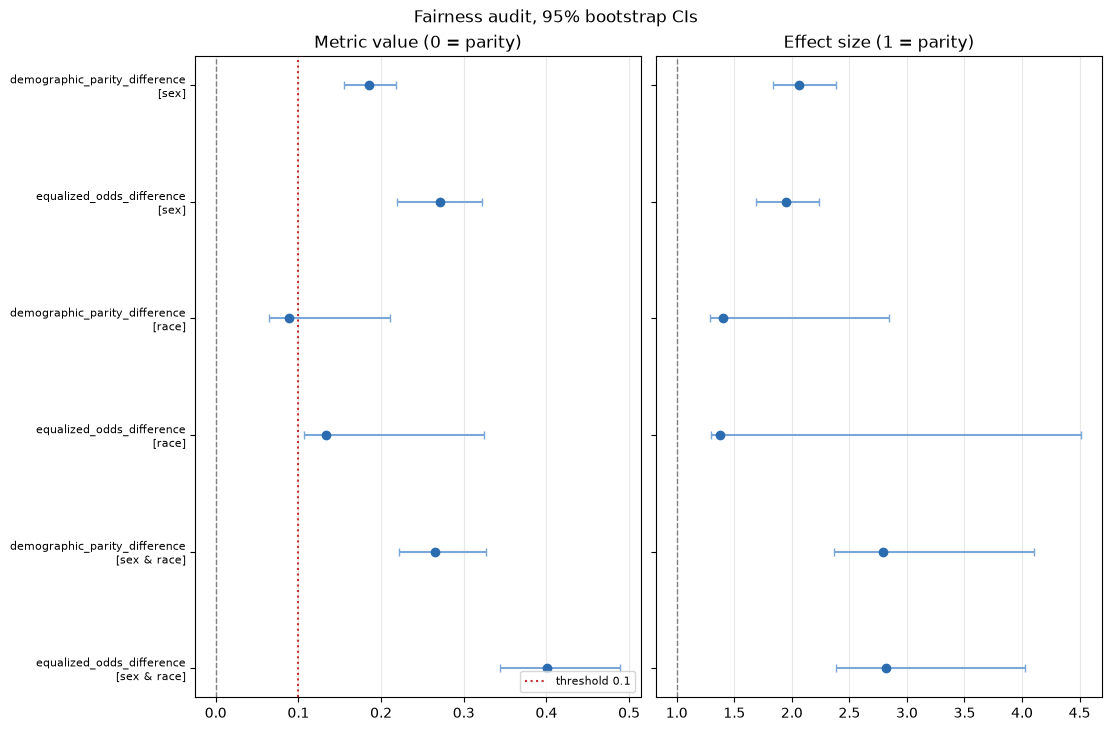

In [18]:
fig = plot_report(rep_bh, threshold=0.10)

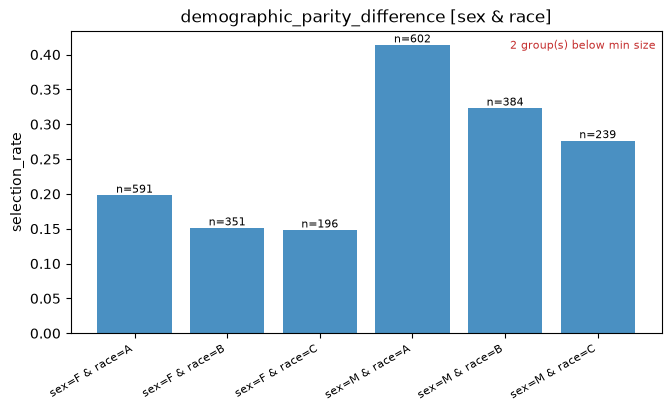

In [19]:
from fairmeasure import plot_group_values
fig = plot_group_values(rep_bh.get("demographic_parity_difference", "sex & race"))

In [20]:
paths = save_report_plots(rep_bh, "audit_plots", threshold=0.10)
print(len(paths), "files written, e.g.", paths[0])

7 files written, e.g. audit_plots\fairness_summary.png


## Caveats

* The "difference" metrics are max minus min, so they can't go below 0 and are slightly biased upwards on small samples. Percentile CIs can therefore sit a little above the point estimate. That's another reason to use `min_group_size`.
* Effect sizes are infinite when the lowest group rate is exactly 0 (nothing to divide by). They're reported as `inf` and dropped to `null` in JSON.
* Permutation p-values test "group is unrelated to the outcome". They're there to feed the multiple-comparison correction, not as a replacement for looking at effect sizes.